# Advanced Data Preparation with Python (Apartment Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped rental apartment data from Zurich. It is an exercise: complete the empty code cells. The solution is in advanced_data_preparation_apartment_data_solution.ipynb. 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [2]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 V4 Data Preparation


## Importing data

In [3]:
# Read the data to a pandas data frame
df_ap02_V4_1 = pd.read_csv('./apartments_data_zuerich.csv',   #CSV aus dem aktuellen Arbeitsordner einlesen und als df speichern
                 sep=',',                           #Komma als Trennzeichen verwenden
                 encoding='utf-8')                  #Datei mit UTF-8-Zeichenkodierung lesen

# Show first records of data frame
df_ap02_V4_1.head()                                           #Erste fünf Zeilen der Tabelle anzeigen

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86..."
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,..."
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri..."
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,..."
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8..."


## Count number of rows and columns in the data frame

In [4]:
# Dimension (rows, columns)
print('Dimension:', df_ap02_V4_1.shape)               #Anzahl Zeilen und Spalten als (Zeilen, Spalten) anzeigen

# Number of rows
print('Number of rows:', df_ap02_V4_1.shape[0])       #Anzahl Zeilen (Datensätze) anzeigen

# Number of columns
print('Number of columns:', df_ap02_V4_1.shape[1])    #Anzahl Spalten (Merkmale) anzeigen

Dimension: (1008, 7)
Number of rows: 1008
Number of columns: 7


## Get data types (raw-format from web scraper)

In [5]:
# Get data types (note that in pandas, a string is referred to as 'object')
display(df_ap02_V4_1.dtypes)             #Datentyp jeder Spalte anzeigen; Textspalten können je nach pandas-Version als object, str oder string erscheinen

web-scraper-order        str
web-scraper-start-url    str
rooms_area_price_raw     str
address_raw              str
price_raw                str
description_raw          str
text_raw                 str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract number of rooms
#### 4 Zimmer, 7,5 Zimmer etc. in rooms_area_price_raw → 4, 7.5 etc. in rooms

In [6]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []                                                      #Leere Liste für die extrahierten Zimmerzahlen erstellen
for i in df_ap02_V4_1['rooms_area_price_raw']:                  #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", i)               #Ganze Zahl oder Dezimalzahl mit Komma vor Zimmer finden; "3,5 Zimmer" ergibt ["3,5"]
    try:                                                        #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip().replace(',', '.')                    #Ersten Treffer nehmen, äusseren Leerraum entfernen und Komma durch Punkt ersetzen
    except IndexError:                                          #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                               #Fehlenden Wert verwenden
    rooms.append(d2)                                            #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_ap02_V4_1['rooms'] = pd.Series(rooms, dtype="float64")       #Zahlentexte als neue Dezimalzahlspalte speichern; None wird zu NaN

# Show first records of data frame
df_ap02_V4_1[['rooms_area_price_raw', 'rooms']].head()          #Rohtext und extrahierte Zimmerzahl für die ersten fünf Zeilen anzeigen

,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


### Extract living area
#### 24 m², 19 m² etc. in rooms_area_price_raw → 24, 19 in area

In [7]:
# Extract values from 'rooms_area_price_raw' strings
area = []                                                               #Leere Liste für die extrahierten Flächen erstellen
for i in df_ap02_V4_1['rooms_area_price_raw']:                          #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"(\d+)\s*m²", i)                                   #Ganze Zahl vor m² finden; "3 Zimmer, 49 m²" ergibt ["49"]
    try:                                                                #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                              #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                                  #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                                       #Fehlenden Wert verwenden
    area.append(d2)                                                     #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_ap02_V4_1['area'] = pd.Series(area, dtype="Int64")                   #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_ap02_V4_1[['rooms_area_price_raw', 'area']].head()                   #Rohtext und extrahierte Fläche für die ersten fünf Zeilen anzeigen

,rooms_area_price_raw,area
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


### Extract rental price
#### CHF 4345.—, CHF 4242.— etc. in price raw → 4345, 4242 etc. in price

In [8]:
# Extract values from 'price_raw' strings
price = []                                                      #Leere Liste für die extrahierten Preise erstellen
for i in df_ap02_V4_1['price_raw']:                             #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"CHF\s*(\d+)\.—", i)                       #Ganze Zahl zwischen CHF und .— finden; "CHF 1441.—" ergibt ["1441"]
    try:                                                        #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                      #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                          #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                               #Fehlenden Wert verwenden
    price.append(d2)                                            #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_ap02_V4_1['price'] = pd.Series(price, dtype="Int64")         #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_ap02_V4_1[['price_raw', 'price']].head()                     #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

,price_raw,price
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


### Get data types of all variables, including the new ones

In [9]:
# Get data types of all variables
display(df_ap02_V4_1.dtypes)  #Datentyp jeder Spalte anzeigen, einschliesslich der neu erstellten Spalten

web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms                    float64
area                       Int64
price                      Int64
dtype: object

## Count and remove missing values

In [10]:
# Count missing values
print(f"Number of missing values: {pd.isna(df_ap02_V4_1).sum().sum()}") 
#Fehlende Werte je Spalte zählen und zur Gesamtzahl fehlender Zellen addieren
#isna(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl; f"...{...}": Ergebnis in Text einsetzen

# Drop rows with missing values (if any)
df_ap02_V4_1 = df_ap02_V4_1.dropna().reset_index(drop=True)
#Zeilen mit mind. einem fehlenden Wert entfernen und Index ab 0 neu nummerieren; alten Index verwerfen
#dropna(): Zeilen mit fehlenden Werten entfernen; reset_index(): Index ab 0 neu vergeben; drop=True: alten Index nicht als Spalte behalten


Number of missing values: 157


## Count and remove duplicated values

In [11]:
# Count duplicated values
print("Number of duplicated values:",
      df_ap02_V4_1[['web-scraper-order']].duplicated().sum())
#Zusätzliche Zeilen mit derselben web-scraper-order zählen; erster Eintrag zählt nicht als Duplikat
#[['web-scraper-order']]: nur diese Spalte prüfen; duplicated(): zusätzliche Einträge = True; sum(): True-Werte zählen

# Drop rows with duplicated values (if any)
df_ap02_V4_1 = df_ap02_V4_1.drop_duplicates().reset_index(drop=True)
#Vollständig gleiche Zeilen entfernen, ersten Eintrag behalten und Index ab 0 neu nummerieren
#drop_duplicates(): vergleicht alle Spalten; reset_index(): neuer Index; drop=True: alten Index verwerfen

# Dimension (rows, columns)
print('\nDimension:', df_ap02_V4_1.shape)
#Verbleibende Anzahl Zeilen und Spalten anzeigen
#\n: Zeilenumbruch vor der Ausgabe; shape: (Zeilenanzahl, Spaltenanzahl)

Number of duplicated values: 0

Dimension: (861, 10)


## Use string manipulation methods to create additional variables from the apartment descriptions.

### Change strings in 'description_raw' and 'text_raw' to uppercase 

In [12]:
# Change strings in 'description_raw' to uppercase
df_ap02_V4_1['description_raw'] = df_ap02_V4_1['description_raw'].str.upper()   #Beschreibungstexte in Grossbuchstaben umwandeln und zurückspeichern
                                                                                #.str: Textmethoden auf die Spalte anwenden; upper(): Buchstaben
                                                                                #grossschreiben, Zahlen und Satzzeichen bleiben gleich
print('Description:\n', df_ap02_V4_1['description_raw'].head(5), '\n')          #Erste fünf Beschreibungen anzeigen; \n: Zeilenumbruch

# Change strings in 'text_raw' to uppercase
df_ap02_V4_1['text_raw'] = df_ap02_V4_1['text_raw'].str.upper()                 #Texte in Grossbuchstaben umwandeln und zurückspeichern
                                                                                #.str: Textmethoden auf die Spalte anwenden; upper(): Buchstaben grossschreiben
print('Text:\n', df_ap02_V4_1['text_raw'].head(5))                              #Erste fünf Texte anzeigen; \n: Zeilenumbruch nach der Beschriftung

Description:
 0                   «GEMÜTLICHE WOHNUNG IM GRÜNEN»
1    «ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»
2             «2 BEDROOM APARTMENT SENIOR BALCONY»
3             «2 BEDROOM APARTMENT JUNIOR TERRACE»
4                       «2 BEDROOM APARTMENT MINI»
Name: description_raw, dtype: str 

Text:
 0    3 ZIMMER, 49 M², CHF 1441.—NEUHUSSTRASSE 6, 86...
1    3,5 ZIMMER, 65 M², CHF 1850.—ZÜRCHERSTRASSE 1,...
2    2 ZIMMER, 54 M², CHF 4853.—CRAMERSTRASSE 8-12,...
3    2 ZIMMER, 49 M², CHF 4335.—ROTACHSTRASSE 33, 8...
4    2 ZIMMER, 32 M², CHF 3515.—WOLFRAMPLATZ 1, 804...
Name: text_raw, dtype: str


### Calculate length of strings in 'description_raw' and 'text_raw'

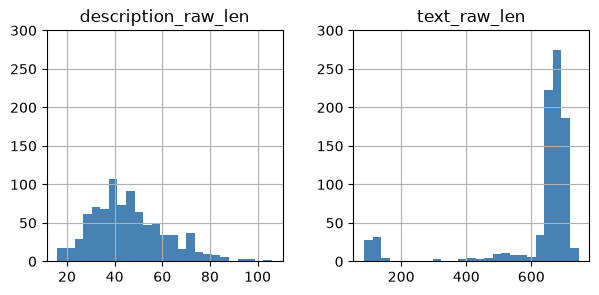

In [13]:
# Length of the strings in 'description_raw'
df_ap02_V4_1['description_raw_len'] = df_ap02_V4_1['description_raw'].str.len() #Zeichenanzahl jeder Beschreibung in einer neuen Spalte speichern
                                                                                #.str.len(): zählt auch Leerzeichen und Satzzeichen

# Length of the strings in 'text_raw'
df_ap02_V4_1['text_raw_len'] = df_ap02_V4_1['text_raw'].str.len()               #Zeichenanzahl jedes Textes in einer neuen Spalte speichern

# Histogram of the length of the strings in 'description_raw' and 'text_raw'
ax = df_ap02_V4_1[['description_raw_len', 'text_raw_len']].hist(bins=25,        #Für jede ausgewählte Spalte ein Histogramm mit 25 Intervallen erstellen
                                                    figsize=(7, 3),             #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                                    color='steelblue')          #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot
for axis in ax.flatten():                                           #flatten(): Achsenanordnung in eine eindimensionale Folge umwandeln; jede Achse einzeln durchlaufen
    axis.set_ylim(0, 300)                                           #set_ylim(): y-Achse des jeweiligen Histogramms auf 0 bis 300 begrenzen

# Display the plot
plt.show()                                                          #Fertige Histogramme anzeigen

### Create binary (0/1) variable 'luxurious'

In [14]:
#Code markiert Wohnungen mit 1, wenn ihre Beschreibung mind. einen der Begriffe LOFT, SEESICHT, PENTHOUSEm LUXUS enthält,
#sonst mit 0, zählt die markierten Wohnungen und zeigt deren Beschreibung, Zimmerzahl, Fläche und Preis an

# Create a pattern which can be used to search the variable 'description_raw'
pattern = 'LOFT|SEESICHT|PENTHOUSE|LUXUS'                                       #Suchmuster festlegen; | bedeutet ODER. Einer der Begriffe genügt

# Create new variable 'luxurious' as binary dummy (0/1) variable
df_ap02_V4_1['luxurious'] = df_ap02_V4_1['description_raw'].str.contains(pat=pattern).astype(int)
                                                                                #Prüft jede Wohnungsbeschreibung: Enthält sie mind. einen Suchbegriff,
                                                                                #wird luxurious = 1, sonst 0. str.contains(pat=pattern) sucht die Begriffe aus 
                                                                                #pattern und liefert True bei einem Treffer, sonst False
                                                                                #astype(int): wandelt True in 1 und False in 0 um; diese Zahlen werden in der 
                                                                                #neuen Spalte luxurious gespeichert
                                                                                #Die Schreibweise muss passen: LOFT wird gefunden, Loft oder loft nicht
# Count the number of luxurious apartments
print(df_ap02_V4_1['luxurious'].sum()) #sum(): Einsen addieren und damit Wohnungen mit mindestens einem Treffer zählen

# Show values
df_ap02_V4_1[['description_raw', 'rooms', 'area', 'price',
    'luxurious']].loc[df_ap02_V4_1['luxurious'] == 1]                           #Ausgewählte Spalten nur für luxuriöse Wohnungen anzeigen
                                                                                #[[...]]: Spalten auswählen; .loc[...]: Zeilen mit luxurious == 1 auswählen

22


,description_raw,rooms,area,price,luxurious
64,«SONNIGE ATTIKAWOHNUNG MIT SEESICHT IN RICHTER...,3.5,105,3410,1
85,«2.5-ZIMMER-LOFT WOHNUNG AN TOP LAGE ZU VERMIE...,2.5,64,2560,1
88,«EXKLUSIVE 1.5 ZI LOFT-WOHNUNG IM HOCHHAUS HAR...,1.5,81,3131,1
91,«IN LOFT-IGER HÖHE MIETEN OHNE KAUTION»,1.0,132,3260,1
114,«3 1/2-ZIMMER-WOHNUNG MIT SEESICHT»,3.5,100,5550,1
141,«EXKLUSIVER SEEBLICK: LUXUSWOHNEN AN ZÜRICHS U...,3.5,169,9000,1
150,«WILLKOMMEN IN “WOLLYWOOD” SEESICHT 3.5-ZIMMER...,3.5,100,9150,1
214,«ATTIKA-WOHNUNG IN LOFT-STYLE - 140M2»,3.5,140,3200,1
236,"«MÖBLIERT, TEMPORÄR: 2½ ZIMMER-LOFT IN DÜBENDO...",2.5,55,2417,1
280,«2.5 ZIMMERWOHNUNG MIT SEESICHT UND GARTEN»,2.5,75,6900,1


### Create variable 'price_per_m2'

In [15]:
# Create the new variable
df_ap02_V4_1['price_per_m2'] = round(df_ap02_V4_1['price'] / df_ap02_V4_1['area'], 2)     #Preis jeder Wohnung durch ihre Fläche teilen und als neue Spalte speichern
                                                                                #round(..., 2): Ergebnis auf zwei Nachkommastellen runden, z. B. CHF pro m²

# Show values
df_ap02_V4_1[['description_raw', 'rooms', 'area', 'price', 'luxurious', 'price_per_m2']]  #Ausgewählte Spalten inklusive berechnetem Preis pro m² anzeigen
                                                                    #[[...]]: Mehrere Spalten als Tabelle auswählen; ohne head() keine Begrenzung auf fünf Zeilen

,description_raw,rooms,area,price,luxurious,price_per_m2
0,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,3.0,49,1441,0,29.41
1,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,3.5,65,1850,0,28.46
2,«2 BEDROOM APARTMENT SENIOR BALCONY»,2.0,54,4853,0,89.87
3,«2 BEDROOM APARTMENT JUNIOR TERRACE»,2.0,49,4335,0,88.47
4,«2 BEDROOM APARTMENT MINI»,2.0,32,3515,0,109.84
...,...,...,...,...,...,...
856,"«CHARMANTE WOHNUNG IN HOTTINGEN, NÄHE RÖMERHOF»",3.5,82,2830,0,34.51
857,«HEIMELIGE 4-ZIMMER-WOHNUNG IN WINTERTHUR-HEGI»,4.0,73,1713,0,23.47
858,«EXKLUSIVE WOHNUNG FÜR HÖCHSTE ANSPRÜCHE - MIT...,4.5,110,3500,1,31.82
859,«MODERNE WOHNUNG AN RUHIGER LAGE»,3.0,68,1650,0,24.26


### Include current datetime as time stamp

In [16]:
# Get and format datetime
df_ap02_V4_1['datetime'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")         #Aktuelles Datum und Uhrzeit als Text in jeder Zeile der neuen Spalte speichern
                                                                                #datetime.now(): aktueller Zeitpunkt; strftime(): als Text formatieren
                                                                                #%Y-%m-%d: Jahr-Monat-Tag; %H:%M:%S: Stunde:Minute:Sekunde

# Show values
df_ap02_V4_1[['description_raw', 'rooms', 'area', 'price', 'luxurious',
    'price_per_m2', 'datetime']]                                                #Ausgewählte Spalten inklusive Zeitstempel anzeigen
                                                                                #[[...]]: Spalten und ihre Reihenfolge für die Anzeige festlegen

,description_raw,rooms,area,price,luxurious,price_per_m2,datetime
0,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,3.0,49,1441,0,29.41,2026-10-31 01:16:58
1,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,3.5,65,1850,0,28.46,2026-10-31 01:16:58
2,«2 BEDROOM APARTMENT SENIOR BALCONY»,2.0,54,4853,0,89.87,2026-10-31 01:16:58
3,«2 BEDROOM APARTMENT JUNIOR TERRACE»,2.0,49,4335,0,88.47,2026-10-31 01:16:58
4,«2 BEDROOM APARTMENT MINI»,2.0,32,3515,0,109.84,2026-10-31 01:16:58
...,...,...,...,...,...,...,...
856,"«CHARMANTE WOHNUNG IN HOTTINGEN, NÄHE RÖMERHOF»",3.5,82,2830,0,34.51,2026-10-31 01:16:58
857,«HEIMELIGE 4-ZIMMER-WOHNUNG IN WINTERTHUR-HEGI»,4.0,73,1713,0,23.47,2026-10-31 01:16:58
858,«EXKLUSIVE WOHNUNG FÜR HÖCHSTE ANSPRÜCHE - MIT...,4.5,110,3500,1,31.82,2026-10-31 01:16:58
859,«MODERNE WOHNUNG AN RUHIGER LAGE»,3.0,68,1650,0,24.26,2026-10-31 01:16:58


## Discretization of numerical data

In [17]:
# Discretization of the variable 'price_per_m2'
df_ap02_V4_1['price_per_m2_cat'] = pd.cut(df_ap02_V4_1['price_per_m2'],         #Preis pro m² in Klassen einteilen und als neue kategoriale Spalte speichern
                                bins=5,                                         #Wertebereich in fünf gleich breite Intervalle teilen; nicht gleich viele Wohnungen je Klasse
                                labels=['very cheap',                           #Beschriftung der niedrigsten Preisklasse
                                        'cheap',                                #Beschriftung der zweiten Klasse
                                        'normal',                               #Beschriftung der mittleren Klasse
                                        'expensive',                            #Beschriftung der vierten Klasse
                                        'very expensive'])                      #Beschriftung der höchsten Preisklasse

# Show unique values
df_ap02_V4_1['price_per_m2_cat'].unique()                                       #Tatsächlich vorkommende Klassen jeweils einmal anzeigen; keine Häufigkeiten zählen

['very cheap', 'normal', 'expensive', 'cheap', 'very expensive']
Categories (5, str): ['very cheap' < 'cheap' < 'normal' < 'expensive' < 'very expensive']

## One Hot Encoding

In [18]:
# One Hot Encoding of the variable 'price_per_m2_cat'
try:                                                                            #Versuchen, die Kategoriespalte in eigene 0/1-Spalten umzuwandeln
    df_ap02_V4_1 = pd.get_dummies(df_ap02_V4_1,                                 #Ergebnis zurück in df speichern; ursprüngliche Kategoriespalte wird ersetzt
                        columns=['price_per_m2_cat'],                           #Für jede Preiskategorie eine eigene Spalte erstellen
                        drop_first=False)                                       #Alle Kategorien behalten; keine Dummy-Spalte weglassen
except KeyError:                                                                #Falls die angegebene Kategoriespalte nicht vorhanden ist
    print("Dummy variables already exist")                                      #Hinweis ausgeben; möglicherweise wurde die Zelle bereits ausgeführt

# Convert boolean values to integers (0 and 1)
dummy_cols = df_ap02_V4_1.filter(like='price_per_m2_cat').columns               #Namen aller Spalten sammeln, die price_per_m2_cat enthalten
df_ap02_V4_1[dummy_cols] = df_ap02_V4_1[dummy_cols].astype(int)                 #Ausgewählte Dummy-Spalten in ganze Zahlen umwandeln: True → 1, False → 0

# Show values of the new dummy variables
df_ap02_V4_1.filter(like='price_per_m2_cat').head()                             #Erste fünf Zeilen der passenden Spalten anzeigen
                                                                                #filter(like=...): Spalten nach enthaltenem Namensteil auswählen; head(): erste fünf Zeilen

,price_per_m2_cat_very cheap,price_per_m2_cat_cheap,price_per_m2_cat_normal,price_per_m2_cat_expensive,price_per_m2_cat_very expensive
0,1,0,0,0,0
1,1,0,0,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


## Scaling

### Min-Max Scaling

#### By hand

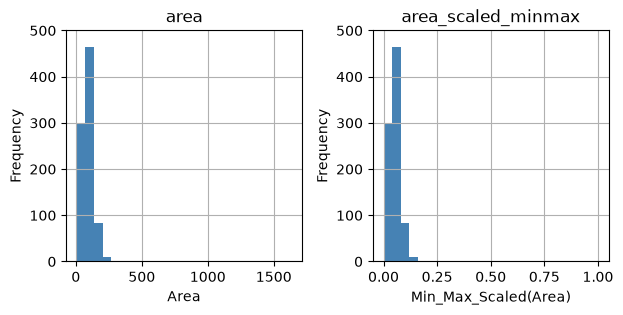

In [19]:
# Min-Max scaling of the variable 'area' (by hand)
df_ap02_V4_1['area_scaled_minmax'] = ((df_ap02_V4_1['area'] - df_ap02_V4_1['area'].min())       #Von jeder Fläche die kleinste Fläche abziehen
                            / (df_ap02_V4_1['area'].max() - df_ap02_V4_1['area'].min()))        #Durch die Spannweite teilen: grösste minus kleinste Fläche
                                                                                                #Ergebnis: kleinste Fläche → 0, grösste → 1; übrige Werte dazwischen

# Histogram of the variable 'area' and 'area_scaled_minmax'
ax = df_ap02_V4_1[['area', 'area_scaled_minmax']].hist(bins=25,                 #Originalflächen und skalierte Flächen als zwei Histogramme darstellen
                                             figsize=(7, 3),                    #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                             color='steelblue')                 #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Min_Max_Scaled(Area)']):         #Jede Diagrammachse zusammen mit ihrer Beschriftung durchlaufen
                                                                                #flatten(): Achsenanordnung abflachen; zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #x-Achse mit der jeweils zugehörigen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #y-Achse beschriften: Anzahl Wohnungen je Intervall

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [20]:
# Min-Max scaling of the variable 'area' (scikit-learn version)
from sklearn.preprocessing import MinMaxScaler                  #MinMaxScaler importieren: Werte standardmässig auf den Bereich 0 bis 1 skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MinMaxScaler() #Scaler-Objekt für die Min-Max-Skalierung erstellen
df_ap02_V4_1['area_scaled_minmax_sklearn'] = scaler.fit_transform(              #Skalierte Flächen in neuer Spalte speichern
    df_ap02_V4_1[['area']]).ravel()                                             #fit_transform(): Minimum und Maximum bestimmen und Werte auf 0 bis 1 skalieren
                                                                                #[['area']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_ap02_V4_1['area_scaled_minmax'],                           #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_ap02_V4_1['area_scaled_minmax_sklearn']))                  #allclose(): Prüfen, ob alle Werte innerhalb kleiner numerischer Toleranzen übereinstimmen

True


### Max-Absolute Scaling

#### By hand

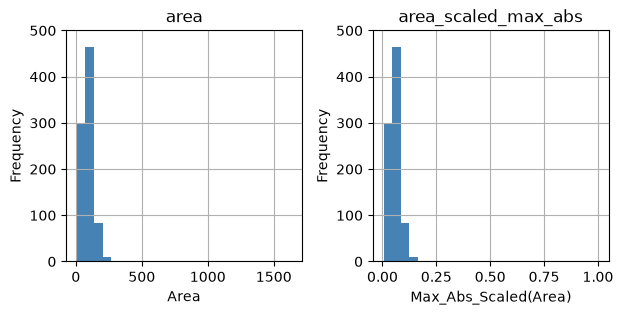

In [21]:
# Max-Absolute scaling of the variable 'area' (by hand)
df_ap02_V4_1['area_scaled_max_abs'] = df_ap02_V4_1['area'] / df_ap02_V4_1['area'].abs().max()       #Jede Fläche durch den grössten Absolutwert der Spalte dividieren
                                                                                #abs(): Absolutwerte bilden; max(): grössten Absolutwert bestimmen
                                                                                #Ergebnis: Werte zwischen -1 und 1 (bei positiven Flächen zwischen 0 und 1)

# Histogram of the variable 'area' and 'area_scaled_max_abs'
ax = df_ap02_V4_1[['area', 'area_scaled_max_abs']].hist(bins=25,                #Originalflächen und skalierte Flächen als zwei Histogramme darstellen
                                             figsize=(7, 3),                    #figsize(): Abbildungsgrösse in Zoll (Breite × Höhe)
                                             color='steelblue')                 #bins=25: 25 Intervalle; color: Balkenfarbe; ax speichert die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Max_Abs_Scaled(Area)']):         #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D abflachen; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf den Bereich 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Häufigkeit je Intervall)

# Display the plot
plt.show()                                                                      #Histogramme anzeigen

#Max-Absolute-Skalierung verändert die Grössenordnung, nicht die Form der Verteilung
#Beide Histogramme zeigen deshalb dieselbe Verteilungsform, aber unterschiedliche x-Achsenwerte

#### scikit-learn version

In [22]:
# Max-Absolute scaling of the variable 'area' (scikit-learn version)
from sklearn.preprocessing import MaxAbsScaler                             #MaxAbsScaler importieren: Werte durch den grössten Absolutwert skalieren (Bereich -1 bis 1)

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MaxAbsScaler()                                                         #Scaler-Objekt für die Max-Absolute-Skalierung erstellen
df_ap02_V4_1['area_scaled_max_abs_sklearn'] = scaler.fit_transform(             #Skalierte Flächen in neuer Spalte speichern
    df_ap02_V4_1[['area']]).ravel()                                             #fit_transform(): Grössten Absolutwert bestimmen und alle Werte dadurch dividieren
                                                                                #[['area']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_ap02_V4_1['area_scaled_max_abs'],                          #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_ap02_V4_1['area_scaled_max_abs_sklearn']))                 #allclose(): Prüfen, ob alle Werte innerhalb kleiner numerischer Toleranzen übereinstimmen
                                                                                #Ergebnis True: Beide Verfahren liefern praktisch identische Werte
                                                                                #Erkenntnis: MaxAbsScaler() automatisiert die manuelle Max-Absolute-Skalierung
                                                                                #Voraussetzung: Die Spalte 'area_scaled_max_abs' muss bereits existieren

True


### Robust Scaling

#### By hand

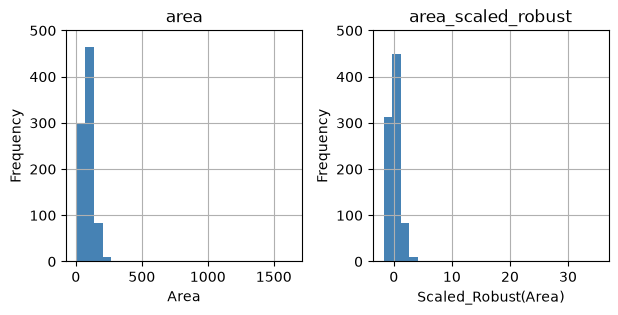

In [23]:
# Robust scaling of the variable 'area' (by hand)
df_ap02_V4_1['area_scaled_robust'] = (df_ap02_V4_1['area'] - df_ap02_V4_1['area'].median()) / \
                           (df_ap02_V4_1['area'].quantile(0.75)                 #quantile(0.75): 75. Perzentil (Q3) bestimmen
                            - df_ap02_V4_1['area'].quantile(0.25))              #quantile(0.25): 25. Perzentil (Q1) bestimmen
                                                                                #median(): mittleren Wert bestimmen (50. Perzentil)
                                                                                #Formel: (Wert - Median) / (Q3 - Q1); Q3 - Q1 = IQR
                                                                                #Ergebnis: Median wird 0; Skalierung ist weniger empfindlich gegenüber Ausreissern

# Histogram of the variable 'area' and 'area_scaled_robust'
ax = df_ap02_V4_1[['area', 'area_scaled_robust']].hist(bins=25,                 #Originale und robust skalierte Flächen als zwei Histogramme darstellen
                                             figsize=(7, 3),                    #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                             color='steelblue')                 #bins=25: 25 Intervalle; color: Balkenfarbe
                                                                                #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert
                                                                                #Werte können negativ oder grösser als 1 sein (kein fester Wertebereich)

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Scaled_Robust(Area)']):          #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Wohnungen je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [24]:
# Robust scaling of the variable 'area' (scikit-learn version)
from sklearn.preprocessing import RobustScaler                                  #RobustScaler importieren: Werte anhand von Median und IQR skalieren
                                                                                #(weniger empfindlich gegenüber Ausreissern)

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = RobustScaler()                                                         #Scaler-Objekt für die robuste Skalierung erstellen
df_ap02_V4_1['area_scaled_robust_sklearn'] = scaler.fit_transform(              #Robust skalierte Wohnungsflächen in neuer Spalte speichern
    df_ap02_V4_1[['area']]).ravel()                                             #fit_transform(): Median und IQR bestimmen und Werte mit (Wert - Median) / IQR skalieren
                                                                                #[['area']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_ap02_V4_1['area_scaled_robust'],                           #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_ap02_V4_1['area_scaled_robust_sklearn']))                  #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                                #True: Beide Verfahren liefern praktisch identische Ergebnisse
                                                                                #Erkenntnis: RobustScaler() automatisiert die manuelle Skalierung mit Median und IQR
                                                                                #Der Median wird 0; Ausreisser bleiben erhalten, beeinflussen die Skalierung aber weniger
                                                                                #Voraussetzung: Die manuell skalierte Spalte 'area_scaled_robust' muss bereits existieren

True


## Standardization

### Z-score Normalization

#### By hand

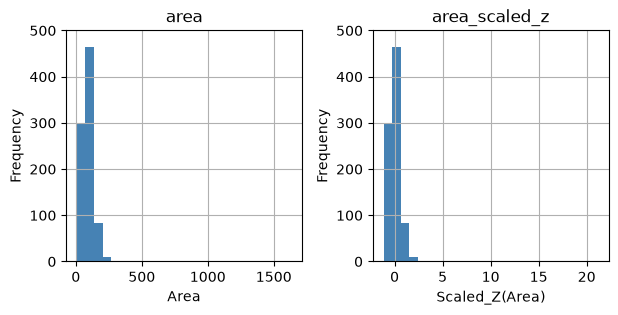

In [25]:
# Z-score Normalization of the variable 'area' (by hand)
df_ap02_V4_1['area_scaled_z'] = (df_ap02_V4_1['area'] - df_ap02_V4_1['area'].mean()) / df_ap02_V4_1['area'].std()   
                                                                                #Von jeder Fläche den Mittelwert abziehen und durch die Standardabweichung teilen
                                                                                #mean(): arithmetischen Mittelwert berechnen; std(): Standardabweichung bestimmen
                                                                                #Ergebnis: Mittelwert ≈ 0 und Standardabweichung ≈ 1
                                                                                #Werte über dem Mittelwert werden positiv, darunter negativ; kein fester Wertebereich

# Histogram of the variable 'area' and 'area_scaled_z'
ax = df_ap02_V4_1[['area', 'area_scaled_z']].hist(bins=25,                      #Originale und standardisierte Wohnungsflächen als zwei Histogramme darstellen
                                        figsize=(7, 3),                         #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                        color='steelblue')                      #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                                #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert
                                                                                #Standardisierung erzeugt keine Normalverteilung, falls diese vorher nicht vorlag

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Scaled_Z(Area)']):               #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Wohnungen je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [26]:
# Z-score Normalization of the variable 'area' (scikit-learn version)
from sklearn.preprocessing import StandardScaler                                #StandardScaler importieren: Werte auf Mittelwert 0 und Standardabweichung 1 standardisieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = StandardScaler()                                                       #Scaler-Objekt für die Z-Score-Standardisierung erstellen
df_ap02_V4_1['area_scaled_z_sklearn'] = scaler.fit_transform(                   #Standardisierte Wohnungsflächen in neuer Spalte speichern
    df_ap02_V4_1[['area']]).ravel()                                             #fit_transform(): Mittelwert und Standardabweichung bestimmen und Werte standardisieren
                                                                                #[['area']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly
print(np.allclose(df_ap02_V4_1['area_scaled_z'],                                #Manuelle und sklearn-Standardisierung miteinander vergleichen
                  df_ap02_V4_1['area_scaled_z_sklearn']))                       #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                                #Erwartet False: pandas.std() verwendet n-1, StandardScaler verwendet n
                                                                                #Erkenntnis: Unterschiedliche Berechnung der Standardabweichung führt zu leicht anderen Werten

# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)
z_ddof0 = (df_ap02_V4_1['area'] - df_ap02_V4_1['area'].mean()) / df_ap02_V4_1['area'].std(ddof=0)     #Z-Score manuell mit derselben Standardabweichung wie sklearn berechnen
                                                                                #std(ddof=0): Durch n statt n-1 teilen (Populationsstandardabweichung)
                                                                                #ddof: Freiheitsgradkorrektur; Standardwert bei pandas ist 1
print(np.allclose(z_ddof0, df_ap02_V4_1['area_scaled_z_sklearn']))              #Manuelle Berechnung mit ddof=0 und sklearn vergleichen
                                                                                #Erwartet True: Beide verwenden dieselbe Berechnung und liefern praktisch identische Werte

False
True


## Transformation

### Log-Transformation

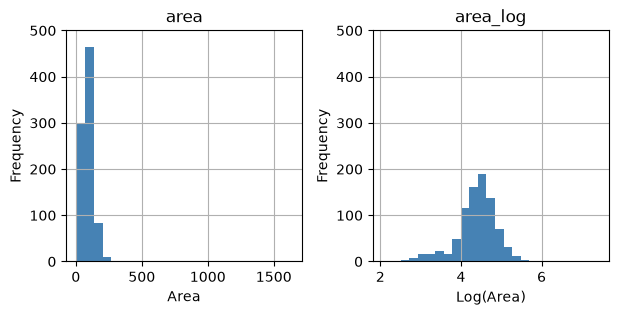

In [27]:
# Log-Transformation of the variable 'area'
df_ap02_V4_1['area_log'] = np.log(df_ap02_V4_1['area'])                         #Wohnungsflächen logarithmieren und in neuer Spalte speichern
                                                                                #np.log(): natürlichen Logarithmus (Basis e) für jeden Wert berechnen
                                                                                #Voraussetzung: Flächen müssen > 0 sein, da log(0) nicht definiert ist
                                                                                #Erkenntnis: Grosse Werte werden stärker komprimiert; Rechtsschiefe kann abnehmen

# Histogram of the variable 'area' and 'area_log'
ax = df_ap02_V4_1[['area', 'area_log']].hist(bins=25,                           #Originale und logarithmierte Wohnungsflächen als zwei Histogramme darstellen
                                   figsize=(7, 3),                              #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                   color='steelblue')                           #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                                #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                                #Erkenntnis: Anders als beim Scaling kann die Transformation die Verteilungsform verändern
                                                                                #Eine rechtsschiefe Verteilung kann symmetrischer werden; Normalverteilung nicht garantiert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Log(Area)']):                    #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Wohnungen je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

### SQRT-Transformation

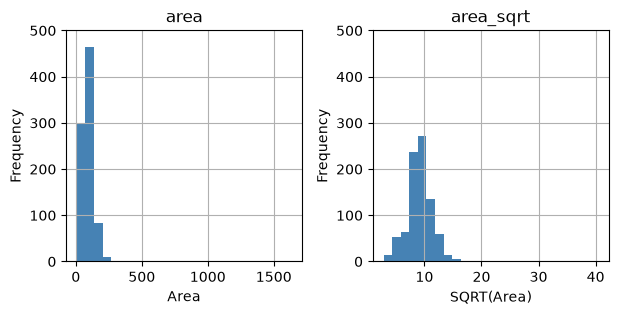

In [28]:
# SQRT-Transformation of the variable 'area'
df_ap02_V4_1['area_sqrt'] = np.sqrt(df_ap02_V4_1['area'])                       #Quadratwurzel jeder Wohnungsfläche berechnen und in neuer Spalte speichern
                                                                                #np.sqrt(): Quadratwurzel jedes Werts berechnen (z. B. √100 = 10)
                                                                                #Voraussetzung: Werte müssen >= 0 sein; negative Werte ergeben NaN
                                                                                #Erkenntnis: Grosse Werte werden stärker komprimiert als kleine; Rechtsschiefe kann abnehmen
                                                                                #Im Gegensatz zu np.log() sind auch Nullwerte erlaubt (√0 = 0)

# Histogram of the variable 'area' and 'area_sqrt'
ax = df_ap02_V4_1[['area', 'area_sqrt']].hist(bins=25,                          #Originale und wurzeltransformierte Wohnungsflächen als zwei Histogramme darstellen
                                    figsize=(7, 3),                             #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                    color='steelblue')                          #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                                #Erkenntnis: SQRT kann die Verteilungsform verändern und Rechtsschiefe reduzieren
                                                                                #Die Transformation ist schwächer als die Logarithmierung bei grossen Werten

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'SQRT(Area)']):                   #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Wohnungen je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

### Box-Cox Transformation

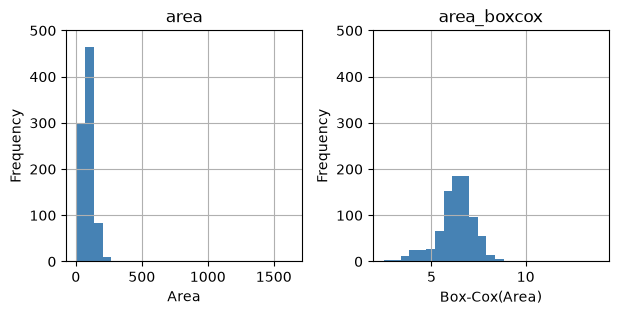

In [29]:
# Import the boxcox function from scipy
from scipy.stats import boxcox                                                  #boxcox() importieren: Werte mittels Box-Cox-Transformation umrechnen, um Schiefe zu reduzieren

# Box-Cox Transformation of the variable 'area'
df_ap02_V4_1['area_boxcox'], _ = boxcox(df_ap02_V4_1['area'])                   #Wohnungsflächen transformieren und in neuer Spalte speichern
                                                                                #boxcox(): optimale Transformation anhand eines Parameters Lambda (λ) bestimmen
                                                                                #Rückgabe: transformierte Werte und geschätztes Lambda; _ ignoriert Lambda
                                                                                #Voraussetzung: Alle Werte müssen > 0 sein (keine Nullwerte oder negativen Werte)
                                                                                #Erkenntnis: Kann Rechtsschiefe reduzieren und Daten einer Normalverteilung annähern
                                                                                #Lambda bestimmt die Stärke der Transformation (λ=0 entspricht Logarithmierung)

# Histogram of the variable 'area' and 'area_boxcox'
ax = df_ap02_V4_1[['area', 'area_boxcox']].hist(bins=25,                        #Originale und Box-Cox-transformierte Wohnungsflächen als zwei Histogramme darstellen
                                      figsize=(7, 3),                           #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                      color='steelblue')                        #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                                #Erkenntnis: Box-Cox kann die Verteilungsform verändern und Schiefe reduzieren
                                                                                #Eine Normalverteilung wird dadurch nicht garantiert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Box-Cox(Area)']):                #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Wohnungen je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

## Combining & organizing data

### Reading rental apartment data with geocoded addresses

In [30]:
# Meaning of variables
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)
df_geo = pd.read_csv('apartments_data_geocoded.csv',                            #CSV-Datei direkt aus dem aktuellen Arbeitsverzeichnis einlesen
                     sep=';',                                                   #sep: Semikolon als Trennzeichen verwenden
                     encoding='utf-8')                                          #encoding: UTF-8-Zeichenkodierung verwenden

# Show data
df_geo.head()                                                                   #head(): Die ersten 5 Zeilen des DataFrames anzeigen

,web-scraper-order,address,lat,lon,bfs_name,bfs_number
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",47.252171,8.845797,Rüti (ZH),118
1,1693998201-2,"Zürcherstrasse 1, 8173 Neerach, ZH",47.513332,8.474851,Neerach,88
2,1693998201-5,"Rotachstrasse 33, 8003 Zürich, ZH",47.370792,8.514748,Zürich,261
3,1693998201-16,"Wolframplatz 1, 8045 Zürich, ZH",47.362282,8.522193,Zürich,261
4,1693998205-25,"Badenerstrasse 67, 8953 Dietikon, ZH",47.407925,8.392561,Dietikon,243


### Join geo-information to rental apartment data using .merge()

In [31]:
# Merge geo-information to the apartment data (the key is 'web-scraper-order')
df_merged = df_ap02_V4_1.merge(df_geo[['web-scraper-order',                     #Nur die benötigten Spalten aus dem Geo-DataFrame auswählen
                                'lat',                                          #Geografischer Breitengrad
                                'lon',                                          #Geografischer Längengrad
                                'bfs_number',                                   #Offizielle Gemeindenummer des Bundesamts für Statistik
                                'bfs_name']],                                   #Offizieller Gemeindename
                        on="web-scraper-order")                                 #merge(): Beide DataFrames über die gemeinsame Schlüsselspalte verbinden
                                                                                #on: Spalte, deren Werte in beiden DataFrames übereinstimmen müssen
                                                                                #Standardmässig how='inner': Nur Datensätze mit passendem Schlüssel in beiden Tabellen übernehmen
                                                                                #df2: Neuer DataFrame mit Wohnungsdaten und zusätzlichen geografischen Informationen
                                                                                #Erkenntnis: Die bestehenden Spalten werden um lat, lon, bfs_number und bfs_name ergänzt
                                                                                #Achtung: Doppelte Schlüssel können zu zusätzlichen Zeilen führen; fehlende Treffer entfallen

# Show data
df_merged[['web-scraper-order',                                                 #Eindeutige Kennnummer des Wohnungsangebots
     'address_raw',                                                             #Adresse der Wohnung
     'price',                                                                   #Mietpreis
     'price_per_m2',                                                            #Berechneter Mietpreis pro Quadratmeter
     'area',                                                                    #Wohnungsfläche
     'rooms',                                                                   #Anzahl Zimmer
     'lat',                                                                     #Geografischer Breitengrad
     'lon',                                                                     #Geografischer Längengrad
     'bfs_number',                                                              #Gemeindenummer
     'bfs_name']].head()                                                        #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                                                                                #Erkenntnis: Wohnungsmerkmale und geografische Informationen stehen nun gemeinsam in einer Tabelle

,web-scraper-order,address_raw,price,price_per_m2,area,rooms,lat,lon,bfs_number,bfs_name
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",1441,29.41,49,3.0,47.252171,8.845797,118,Rüti (ZH)
1,1693998201-2,"Zürcherstrasse 1, 8173 Neerach, ZH",1850,28.46,65,3.5,47.513332,8.474851,88,Neerach
2,1693998201-5,"Rotachstrasse 33, 8003 Zürich, ZH",4335,88.47,49,2.0,47.370792,8.514748,261,Zürich
3,1693998201-16,"Wolframplatz 1, 8045 Zürich, ZH",3515,109.84,32,2.0,47.362282,8.522193,261,Zürich
4,1693998205-25,"Badenerstrasse 67, 8953 Dietikon, ZH",3200,30.48,105,3.5,47.407925,8.392561,243,Dietikon


### Reading municipality-level data

In [36]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees
#bfs_number: offizielle Gemeindenummer des Bundesamts für Statistik (BFS)
#bfs_name: offizieller Gemeindename
#pop: Anzahl Einwohner einer Gemeinde
#pop_dens: Bevölkerungsdichte (Einwohner pro km²)
#frg_pct: Anteil ausländischer Einwohner in Prozent
#emp: Anzahl Beschäftigte einer Gemeinde
#Erkenntnis: Diese Daten enthalten zusätzliche Merkmale auf Gemeindeebene, die später mit anderen Daten kombiniert werden können

# Read municipality-level data from the .xlsx file
df_municip = pd.read_excel('./municipality_data.xlsx',                          #Excel-Datei mit Gemeindedaten aus dem aktuellen Arbeitsverzeichnis einlesen
                           sheet_name='data_for_import')                        #sheet_name: Nur das Excel-Tabellenblatt 'data_for_import' einlesen
                                                                                #pd.read_excel(): Excel-Datei lesen und als pandas-DataFrame zurückgeben
                                                                                #df_municip: Neuer DataFrame mit den Merkmalen der Gemeinden
                                                                                #./: Datei liegt direkt im aktuellen Arbeitsverzeichnis (kein Data-Unterordner)

# Show data
df_municip.head(5)                                                              #head(5): Die ersten 5 Zeilen anzeigen

,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp
0,1,Aeugst am Albis,1981,250.442478,14.184755,442.0
1,2,Affoltern am Albis,12303,1161.756374,28.700317,6920.0
2,3,Bonstetten,5572,749.932705,16.564968,1014.0
3,4,Hausen am Albis,3751,275.808824,16.022394,1021.0
4,5,Hedingen,3778,578.560490,16.410799,1478.0


### Join municipality data to rental apartment data using .merge()

In [38]:
#Merge needs a key which must be identical in both data sets
#(here the key is 'bfs_number')
df_municip_merged = df_merged.merge(
    df_municip[
        [
            'bfs_number',                                                       #Nur die benötigten Spalten aus den Gemeindedaten auswählen
            'pop',                                                              #Anzahl Einwohner der Gemeinde
            'pop_dens',                                                         #Bevölkerungsdichte (Einwohner pro km²)
            'frg_pct',                                                          #Anteil ausländischer Einwohner in Prozent
            'emp'                                                               #Anzahl Beschäftigte der Gemeinde
        ]
    ],
    on='bfs_number'                                                             #Gemeindenummer als gemeinsamen Schlüssel verwenden
)                                                                               #merge(): Wohnungs- und Geodaten mit Gemeindedaten verbinden
                                                                                #Standardmässig how='inner': Nur passende Gemeindenummern übernehmen
                                                                                #df_municip_merged: Neuer DataFrame mit Wohnungs-, Geo- und Gemeindedaten
                                                                                #Erkenntnis: Ein zweiter Merge ergänzt die bestehenden Daten um weitere Merkmale
                                                                                #Achtung: Fehlende Schlüsselübereinstimmungen entfallen; doppelte Schlüssel können Zeilen vervielfachen

#Show data
display(
    df_municip_merged[
        [
            'web-scraper-order',                                                #Eindeutige Kennnummer des Wohnungsangebots
            'address_raw',                                                      #Adresse der Wohnung
            'price',                                                            #Mietpreis
            'price_per_m2',                                                     #Berechneter Mietpreis pro Quadratmeter
            'area',                                                             #Wohnungsfläche
            'rooms',                                                            #Anzahl Zimmer
            'lat',                                                              #Geografischer Breitengrad
            'lon',                                                              #Geografischer Längengrad
            'bfs_number',                                                       #Offizielle Gemeindenummer
            'bfs_name',                                                         #Offizieller Gemeindename
            'pop',                                                              #Anzahl Einwohner der Gemeinde
            'pop_dens'                                                          #Bevölkerungsdichte
        ]
    ].head()
)                                                                               #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                                                                                #Erkenntnis: df_municip_merged enthält Wohnungsmerkmale, geografische Daten und Gemeindeinformationen

,web-scraper-order,address_raw,price,price_per_m2,area,rooms,lat,lon,bfs_number,bfs_name,pop,pop_dens
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",1441,29.41,49,3.0,47.252171,8.845797,118,Rüti (ZH),12286,1221.272366
1,1693998201-2,"Zürcherstrasse 1, 8173 Neerach, ZH",1850,28.46,65,3.5,47.513332,8.474851,88,Neerach,3175,525.662252
2,1693998201-5,"Rotachstrasse 33, 8003 Zürich, ZH",4335,88.47,49,2.0,47.370792,8.514748,261,Zürich,420217,4778.994655
3,1693998201-16,"Wolframplatz 1, 8045 Zürich, ZH",3515,109.84,32,2.0,47.362282,8.522193,261,Zürich,420217,4778.994655
4,1693998205-25,"Badenerstrasse 67, 8953 Dietikon, ZH",3200,30.48,105,3.5,47.407925,8.392561,243,Dietikon,27746,2970.663812


## Sorting data

In [42]:
#Sorting data by 'price' and 'area' with highest price above (ascending=False)
df_municip_merged = df_municip_merged.sort_values(
    by=['price', 'area'],                                                       #sort_values(): DataFrame nach mehreren Spalten sortieren
    ascending=False                                                             #ascending=False: Absteigend sortieren (grösste Werte zuerst)
)                                                                               #Zuerst nach 'price' sortieren; bei gleichem Preis entscheidet 'area'
                                                                                #Beide Spalten werden absteigend sortiert, da False für beide gilt
                                                                                #Erkenntnis: Die teuersten Wohnungen stehen oben; bei gleichem Preis jene mit grösserer Fläche
                                                                                #Sortiertes Ergebnis wieder in df_municip_merged speichern

#Show data
display(
    df_municip_merged[
        [
            'web-scraper-order',                                                #Eindeutige Kennnummer des Wohnungsangebots
            'address_raw',                                                      #Adresse der Wohnung
            'price',                                                            #Mietpreis (primäres Sortierkriterium)
            'price_per_m2',                                                     #Berechneter Mietpreis pro Quadratmeter
            'area',                                                             #Wohnungsfläche (sekundäres Sortierkriterium)
            'rooms',                                                            #Anzahl Zimmer
            'lat',                                                              #Geografischer Breitengrad
            'lon',                                                              #Geografischer Längengrad
            'bfs_number',                                                       #Offizielle Gemeindenummer
            'bfs_name',                                                         #Offizieller Gemeindename
            'pop',                                                              #Anzahl Einwohner der Gemeinde
            'pop_dens'                                                          #Bevölkerungsdichte
        ]
    ].head()
)                                                                               #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                                                                                #Erkenntnis: Die fünf zuerst angezeigten Wohnungen haben die höchsten Preise

,web-scraper-order,address_raw,price,price_per_m2,area,rooms,lat,lon,bfs_number,bfs_name,pop,pop_dens
260,1693998265-365,"Gustav-Gull-Platz 4, 8004 Zürich, ZH",9950,71.07,140,4.5,47.379471,8.531120,261,Zürich,420217,4778.994655
261,1693998265-366,"Engweg 8, 8006 Zürich, ZH",9170,65.5,140,4.5,47.385265,8.537632,261,Zürich,420217,4778.994655
144,1693998236-207,"Etzelstrasse 35, 8038 Zürich, ZH",9150,91.5,100,3.5,47.346546,8.530695,261,Zürich,420217,4778.994655
135,1693998236-197,"Utoquai 37, 8008 Zürich, ZH",9000,53.25,169,3.5,47.363682,8.546781,261,Zürich,420217,4778.994655
345,1693998285-475,"Universitätstrasse 41, 8006 Zürich, ZH",8990,64.21,140,4.5,47.380440,8.547943,261,Zürich,420217,4778.994655


## Reshaping data

### Reshaping data using .stack() and .unstack()

In [43]:
# Create a subset of the data (first 5 rows)
df_sub = df_municip_merged[['bfs_name', 'rooms', 'price', 'area']][:5]          #Teilmenge des DataFrames erstellen: 4 ausgewählte Spalten und die ersten 5 Zeilen
                                                                                #[['...']]: Gewünschte Spalten auswählen
                                                                                #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)
                                                                                #Voraussetzung: df3 muss existieren und die angegebenen Spalten enthalten
print('Original shape')                                                         #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                                             #Teilmenge anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .stack()
df_sub_stacked = df_sub.stack()                                                 #stack(): Spalten in die Zeilenebene verschieben (DataFrame → Series)
                                                                                #Ergebnis: Jede Kombination aus ursprünglichem Zeilenindex und Spaltenname erhält einen Wert
                                                                                #Bei 5 Zeilen und 4 Spalten entstehen normalerweise 20 Werte
                                                                                #Standardmässig können fehlende Werte (NaN) beim Stacken entfallen
print('Stacked')                                                                #Überschrift für die umstrukturierte Darstellung ausgeben
print(df_sub_stacked, '\n')                                                     #Gestapelte Daten mit zweistufigem Index (MultiIndex) anzeigen

# Reshape the data back using .unstack()
print('Unstacked (= back to original shape)')                                   #Überschrift für die Rückumwandlung ausgeben
print(df_sub_stacked.unstack())                                                 #unstack(): Innere Indexebene zurück in Spalten umwandeln (Series → DataFrame)
                                                                                #Ergebnis: Ursprüngliche Tabellenstruktur mit 5 Zeilen und 4 Spalten wiederherstellen
                                                                                #Erkenntnis: stack() und unstack() ermöglichen den Wechsel zwischen breiter und langer Darstellung
                                                                                #Achtung: Falls stack() NaN-Werte entfernt hat, können diese beim unstack() wieder als NaN erscheinen

Original shape
    bfs_name  rooms  price  area
260   Zürich    4.5   9950   140
261   Zürich    4.5   9170   140
144   Zürich    3.5   9150   100
135   Zürich    3.5   9000   169
345   Zürich    4.5   8990   140 

Stacked
260  bfs_name    Zürich
     rooms          4.5
     price         9950
     area           140
261  bfs_name    Zürich
     rooms          4.5
     price         9170
     area           140
144  bfs_name    Zürich
     rooms          3.5
     price         9150
     area           100
135  bfs_name    Zürich
     rooms          3.5
     price         9000
     area           169
345  bfs_name    Zürich
     rooms          4.5
     price         8990
     area           140
dtype: object 

Unstacked (= back to original shape)
    bfs_name rooms price area
260   Zürich   4.5  9950  140
261   Zürich   4.5  9170  140
144   Zürich   3.5  9150  100
135   Zürich   3.5  9000  169
345   Zürich   4.5  8990  140


### Reshaping data using .melt()

In [44]:
# Create a subset of the data (first 5 rows)
df_sub = df_municip_merged[['rooms', 'price', 'area']][:5]                      #Teilmenge erstellen: 3 ausgewählte Spalten und die ersten 5 Zeilen
                                                                                #[['rooms', 'price', 'area']]: Gewünschte Spalten auswählen
                                                                                #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)
print('Original shape')                                                         #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                                             #Originalen DataFrame anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .melt()
print('Reshaped using .melt()') #Überschrift für die umstrukturierte Darstellung ausgeben
print(pd.melt(df_sub, id_vars=['rooms'], value_vars=['price', 'area']))         #melt(): Daten vom breiten (Wide) ins lange Format (Long) umwandeln
                                                                                #id_vars=['rooms']: Spalte 'rooms' als Identifikationsvariable beibehalten
                                                                                #value_vars=['price', 'area']: Diese Spalten untereinander in Zeilen umwandeln
                                                                                #Ergebnis: 3 Spalten ('rooms', 'variable', 'value') statt ursprünglich 3 
                                                                                #('rooms', 'price', 'area')
                                                                                #'variable': Enthält die ursprünglichen Spaltennamen ('price' oder 'area')
                                                                                #'value': Enthält die zugehörigen Werte (Mietpreis bzw. Wohnungsfläche)
                                                                                #Bei 5 ursprünglichen Zeilen und 2 value_vars entstehen 10 Zeilen
                                                                                #Erkenntnis: 'rooms' wird für jeden zugehörigen Wert wiederholt; die Daten werden 
                                                                                #nicht aggregiert
                                                                                #Unterschied zu stack(): melt() erzeugt einen DataFrame mit normalen Spalten 
                                                                                #statt einer Series mit MultiIndex

Original shape
     rooms  price  area
260    4.5   9950   140
261    4.5   9170   140
144    3.5   9150   100
135    3.5   9000   169
345    4.5   8990   140 

Reshaped using .melt()
   rooms variable  value
0    4.5    price   9950
1    4.5    price   9170
2    3.5    price   9150
3    3.5    price   9000
4    4.5    price   8990
5    4.5     area    140
6    4.5     area    140
7    3.5     area    100
8    3.5     area    169
9    4.5     area    140


### Pivoting data using .pivot_table()

In [45]:
# Create a pivot table with the mean values per number of rooms
pivot_table = pd.pivot_table(                                                   #pivot_table(): Daten nach Gruppen zusammenfassen und Kennzahlen aggregieren
    df_municip_merged[['rooms', 'price', 'price_per_m2', 'area']],              #Nur die benötigten Spalten aus dem DataFrame auswählen
    index=['rooms'],                                                            #index: Nach Zimmeranzahl gruppieren (eine Zeile pro Zimmeranzahl)
    values={'price': np.mean,                                                   #price: Durchschnittlichen Mietpreis je Zimmeranzahl berechnen
            'price_per_m2': np.mean,                                            #price_per_m2: Durchschnittlichen Quadratmeterpreis berechnen
            'area': np.mean}).round(2)                                          #area: Durchschnittliche Wohnungsfläche berechnen; round(2): Auf 2 Dezimalstellen runden
                                                                                #WICHTIG: values bestimmt die Spalten, nicht die Aggregationsfunktionen!
                                                                                #np.mean im values-Dictionary wird hier ignoriert; der Mittelwert ist bereits die Standardaggregation
                                                                                #Korrekte Zuordnung unterschiedlicher Funktionen erfolgt über aggfunc={'price': np.mean, ...}
                                                                                #Erkenntnis: Alle Wohnungen mit gleicher Zimmeranzahl werden zu einer Zeile zusammengefasst
                                                                                #Bsp.: Alle 3-Zimmer-Wohnungen ergeben einen durchschnittlichen Preis und eine Durchschnittsfläche

# Format the values to 2 decimal places with trailing zeros
pivot_table = pivot_table.map(                                                  #map(): Formatierungsfunktion auf jeden einzelnen Wert der Pivot-Tabelle anwenden
    lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)                 #lambda x: Anonyme Funktion, die jeden Tabellenwert verarbeitet
                                                                                #isinstance(): Prüft, ob x ein int oder float ist
                                                                                #f"{x:.2f}": Zahl mit genau 2 Nachkommastellen darstellen (z. B. 1200.50)
                                                                                #else x: Andere Werte unverändert übernehmen
                                                                                #Erkenntnis: Auch nachgestellte Nullen werden angezeigt (z. B. 1200.00 statt 1200.0)
                                                                                #Achtung: Formatierte Zahlen werden zu Text (str) und sind nicht mehr direkt numerisch berechenbar
                                                                                #Voraussetzung: DataFrame.map() ist ab pandas 2.1 verfügbar

# Display the pivot table
pivot_table                                                                     #Pivot-Tabelle mit einer Zeile je Zimmeranzahl und den durchschnittlichen Kennzahlen anzeigen
                                                                                #Erkenntnis: Pivot-Tabellen ermöglichen die übersichtliche Aggregation und den Vergleich verschiedener Gruppen

,area,price,price_per_m2
rooms,,,
1.0,32.06,1306.35,50.17
1.5,35.97,2092.05,64.35
2.0,54.48,2138.78,42.20
2.5,67.34,2414.99,37.18
3.0,68.57,1942.66,28.31
3.5,89.50,2664.81,29.71
4.0,96.90,2798.20,29.48
4.5,114.46,3091.17,26.64
5.0,103.50,2773.75,26.59


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-18 12:02:30
Python Version: 3.12.11
-----------------------------------
